# This notebook focuses on exploring the data, showing distributions, finding patterns and correlations.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_parquet("../data/clean.parquet")
df

,White,Black,Result,WhiteElo,BlackElo,TimeControl,ECO,Opening,Termination,event_type,utc_dt,game_id
0,cronopiodano,Magnataroniell,1-0,1708,1690,600+0,B10,Caro-Kann Defense: Euwe Attack,Time forfeit,Rated Classical tournament,2016-12-31 23:00:01,5utpphVs
1,MarlonTeixeira21,caguertti,0-1,1661,1614,300+0,B30,Sicilian Defense: Old Sicilian,Time forfeit,Rated Blitz tournament,2016-12-31 23:00:01,xUn53e0k
2,WinterSnowStorm,theivi,1-0,1968,1893,300+0,D35,"Queen's Gambit Declined: Exchange Variation, P...",Normal,Rated Blitz tournament,2016-12-31 23:00:01,Z5NSdZX4
3,walt_b,james205,0-1,1204,1461,300+0,C44,Ponziani Opening,Normal,Rated Blitz tournament,2016-12-31 23:00:01,RyirpGs3
4,bilbobalboa,PatzerGareBear13,1-0,1859,1772,600+0,C31,"King's Gambit Declined: Falkbeer, Milner-Barry...",Normal,Rated Classical tournament,2016-12-31 23:00:01,f1vd9VBf
...,...,...,...,...,...,...,...,...,...,...,...,...
10574244,arruru,michalisem,0-1,1816,1880,300+0,B21,Sicilian Defense: McDonnell Attack,Normal,Rated Blitz game,2017-01-31 22:59:56,VnBlWWrf
10574245,jozarov,agadmator,0-1,2214,1995,60+0,A31,"English Opening: Symmetrical Variation, Anti-B...",Time forfeit,Rated Bullet game,2017-01-31 22:59:56,gDXG5waf
10574246,asquithbom,glopezp25,0-1,1272,1442,600+0,B01,Scandinavian Defense: Main Line,Normal,Rated Classical game,2017-01-31 22:59:51,dSsRJyZe
10574247,TEBEPIZDA2,CaptainJaco,1-0,1455,1251,600+0,B20,Sicilian Defense: Bowdler Attack,Normal,Rated Classical game,2017-01-31 22:59:59,VAwHk00V


## Game speed

In [3]:
df["speed"] = df["event_type"].str.split().str[1]
df["speed"].value_counts()

speed
Blitz        4895893
Classical    2921599
Bullet       2756757
Name: count, dtype: int64

Three speeds remain after cleaning: Blitz (4,895,893 games), Classical (2,921,599) and Bullet (2,756,757).
Every speed has millions of games, so models can be evaluated separately for each speed. Speed is a candidate categorical feature.

## Openings

Opening names in the export are not fully consistent, while ECO codes are standardised.

In [4]:
df["opening_family"] = (
    df["Opening"].astype("str").str.split(":").str[0].str.split(",").str[0].str.strip()
)
print(df["Opening"].nunique(), "full names")
print(df["opening_family"].nunique(), "families")

2989 full names
204 families


In [5]:
print(f"games without ECO: {df['ECO'].isna().sum():,}")
print(f"ECO codes: {df['ECO'].nunique()}")

eco_counts = df["ECO"].value_counts()
for t in [100, 500, 1000, 5000]:
    kept = eco_counts[eco_counts >= t]
    print(f">= {t:>5} games: {len(kept):>3} ECO codes, {kept.sum() / len(df):.1%} of games")

games without ECO: 5,223
ECO codes: 494
>=   100 games: 432 ECO codes, 99.9% of games
>=   500 games: 348 ECO codes, 99.7% of games
>=  1000 games: 296 ECO codes, 99.4% of games
>=  5000 games: 178 ECO codes, 96.7% of games


In [6]:
op = df.loc[df["ECO"].notna(), ["ECO", "opening_family"]].astype({"ECO": "string"})
pair_counts = op.groupby(["ECO", "opening_family"]).size()

eco_summary = (
    pair_counts.groupby(level="ECO")
    .agg(games="sum", families="size", label=lambda s: s.idxmax()[1])
    .sort_values("games", ascending=False)
)
eco_summary.head(15)

,games,families,label
ECO,,,
A00,703778,25,Van't Kruijs Opening
B01,485595,1,Scandinavian Defense
C00,479499,5,French Defense
A40,459394,19,Horwitz Defense
D00,399821,10,Queen's Pawn Game
B00,353028,17,Nimzowitsch Defense
C41,345799,4,Philidor Defense
C20,336372,5,King's Pawn Game
B20,247423,2,Sicilian Defense


- 2,989 full opening names were reduced to 204 families.
- 5,223 games have no ECO code. In the cleaning notebook these were games that ended before an opening could be classified.
- Some ECO codes are shared by several family names, so one code can group different openings.

ECO code as a categorical feature. Codes below the chosen threshold are grouped into `other`, missing ECO becomes `unknown`.

## Players and ratings

In [7]:
white = df[["White", "WhiteElo", "speed", "utc_dt"]].rename(columns={"White": "player", "WhiteElo": "elo"})
black = df[["Black", "BlackElo", "speed", "utc_dt"]].rename(columns={"Black": "player", "BlackElo": "elo"})

appearances = pd.concat([white, black], ignore_index=True)
print(appearances.shape)
appearances

(21148498, 4)


,player,elo,speed,utc_dt
0,cronopiodano,1708,Classical,2016-12-31 23:00:01
1,MarlonTeixeira21,1661,Blitz,2016-12-31 23:00:01
2,WinterSnowStorm,1968,Blitz,2016-12-31 23:00:01
3,walt_b,1204,Blitz,2016-12-31 23:00:01
4,bilbobalboa,1859,Classical,2016-12-31 23:00:01
...,...,...,...,...
21148493,michalisem,1880,Blitz,2017-01-31 22:59:56
21148494,agadmator,1995,Bullet,2017-01-31 22:59:56
21148495,glopezp25,1442,Classical,2017-01-31 22:59:51
21148496,CaptainJaco,1251,Classical,2017-01-31 22:59:59


In [8]:
appearances = appearances.sort_values("utc_dt")
last_rating = appearances.drop_duplicates(subset=["player", "speed"], keep="last")

last_rating["speed"].value_counts()

speed
Classical    139820
Blitz        136632
Bullet        69374
Name: count, dtype: int64

In [9]:
games_per_player = appearances.groupby(["player", "speed"]).size().rename("n_games")

last_rating = (
    last_rating
    .drop(columns="n_games", errors="ignore")
    .join(games_per_player, on=["player", "speed"])
)
last_rating["n_games"].describe()

count    345826.000000
mean         61.153580
std         149.640174
min           1.000000
25%           2.000000
50%          11.000000
75%          55.000000
max        6670.000000
Name: n_games, dtype: float64

`last_rating` has one row per player and speed. The rating is from the player's last game in January.
Games per pair are very uneven. Median = 11, a quarter of pairs have at most 2 games, three quarters at most 55, maximum 6,670.

## Rating per player, by speed

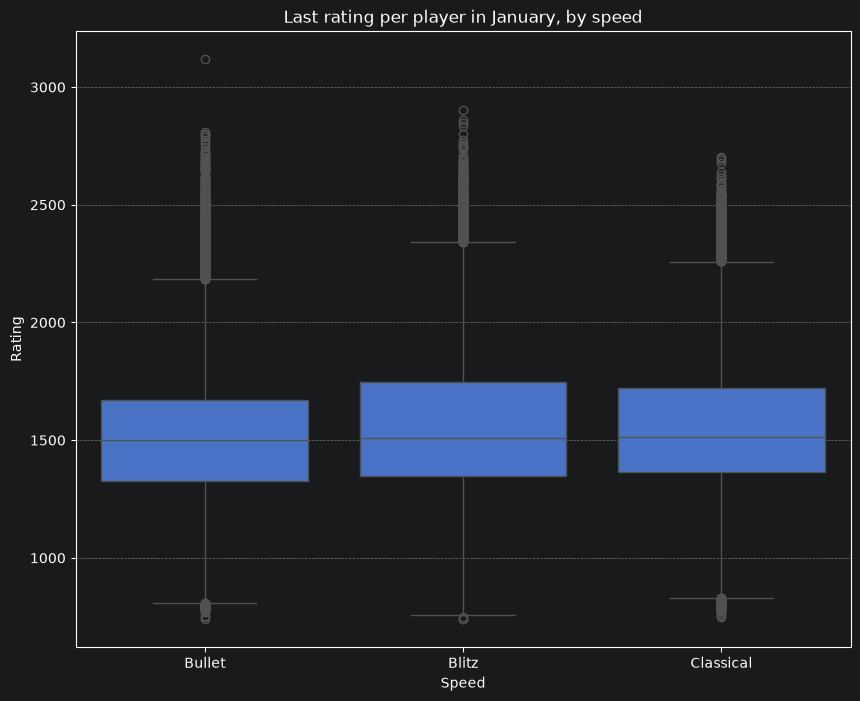

In [10]:
order = ["Bullet", "Blitz", "Classical"]

plt.figure(figsize=(10, 8))
sns.boxplot(
    data=last_rating.astype({"elo": int}),
    x="speed",
    y="elo",
    order=order
)

plt.grid(axis="y", linestyle="--", alpha = 0.6)
plt.title("Last rating per player in January, by speed")
plt.xlabel("Speed")
plt.ylabel("Rating")
plt.show()

In [11]:
print(last_rating["elo"].min())
print(last_rating["elo"].max())

740
3119


## Spike at the starting rating

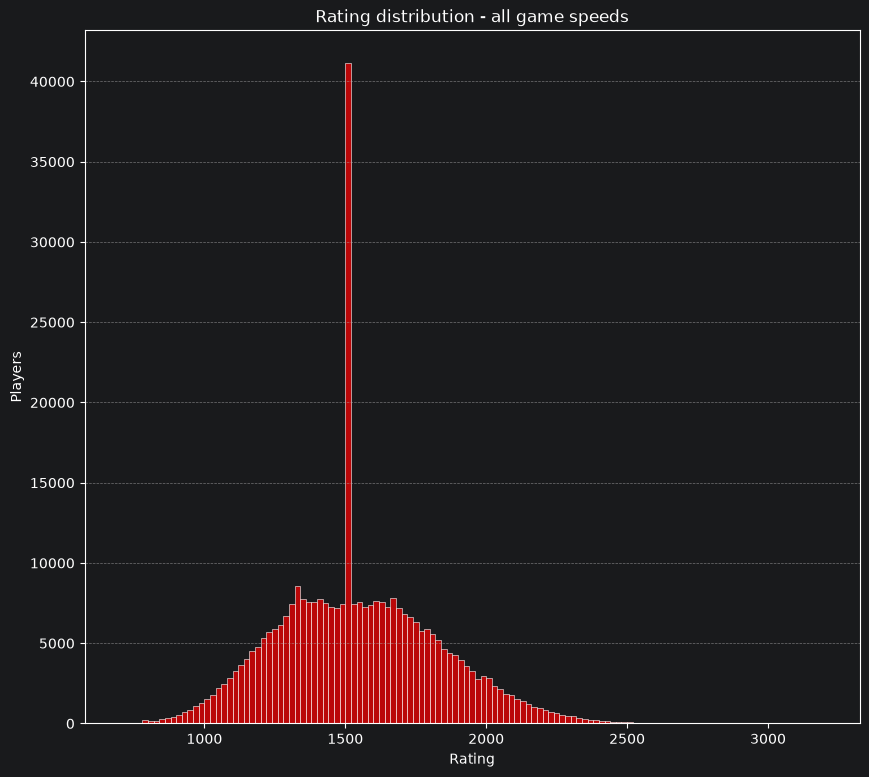

In [12]:
plt.figure(figsize=(10,9))

sns.histplot(
    data=last_rating,
    x="elo",
    binwidth=20,
    binrange=(700, 3200),
    edgecolor="white",
    color="red",
    alpha=0.7,
)

plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.title("Rating distribution - all game speeds")
plt.xlabel("Rating")
plt.ylabel("Players")
plt.show()

In [13]:
at_1500 = last_rating["elo"] == 1500
print(f"players at exactly 1500: {at_1500.sum():,} ({at_1500.mean():.1%})")
print(last_rating.loc[at_1500, "n_games"].value_counts().head())

players at exactly 1500: 34,020 (9.8%)
n_games
1    33393
2      274
3       44
4       30
6       19
Name: count, dtype: int64


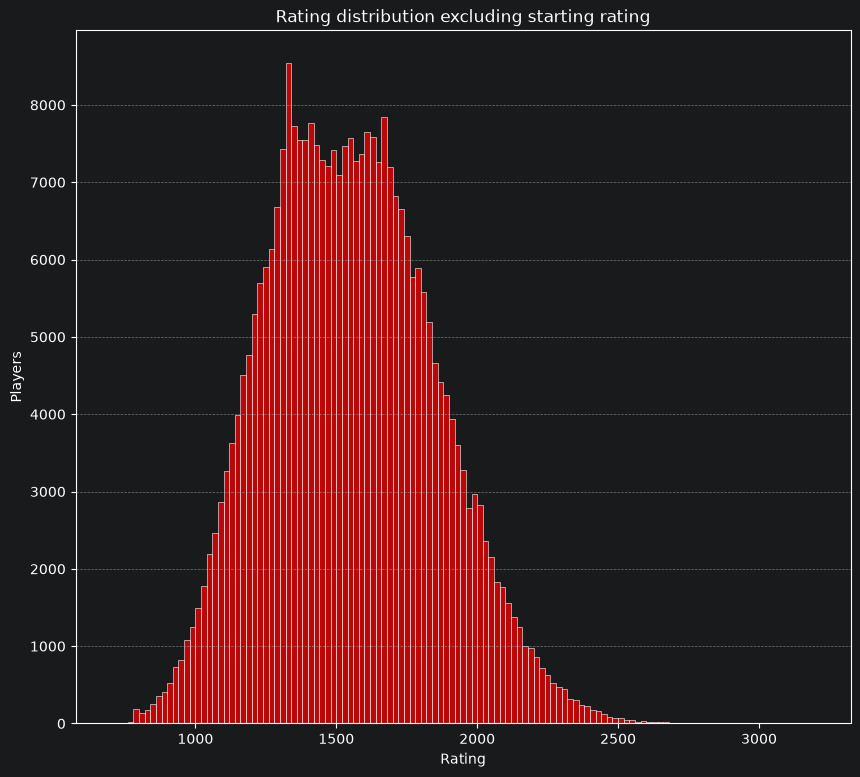

In [14]:
plt.figure(figsize=(10,9))

sns.histplot(
    data=last_rating[last_rating["elo"] != 1500],
    x="elo",
    binwidth=20,
    binrange=(700, 3200),
    edgecolor="white",
    color="red",
    alpha=0.7,
)

plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.title("Rating distribution excluding starting rating")
plt.xlabel("Rating")
plt.ylabel("Players")
plt.show()

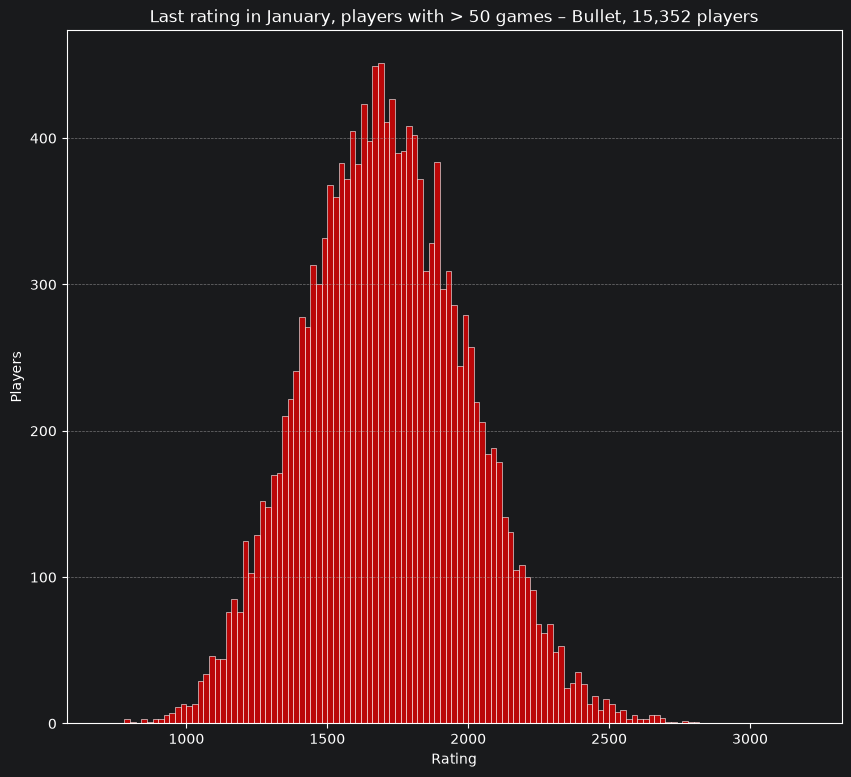

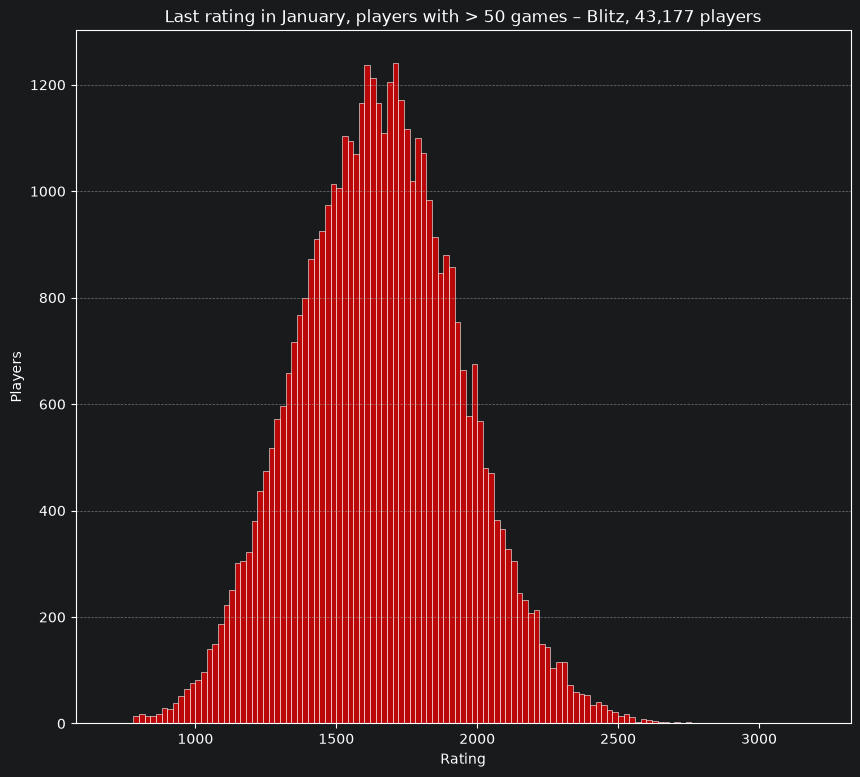

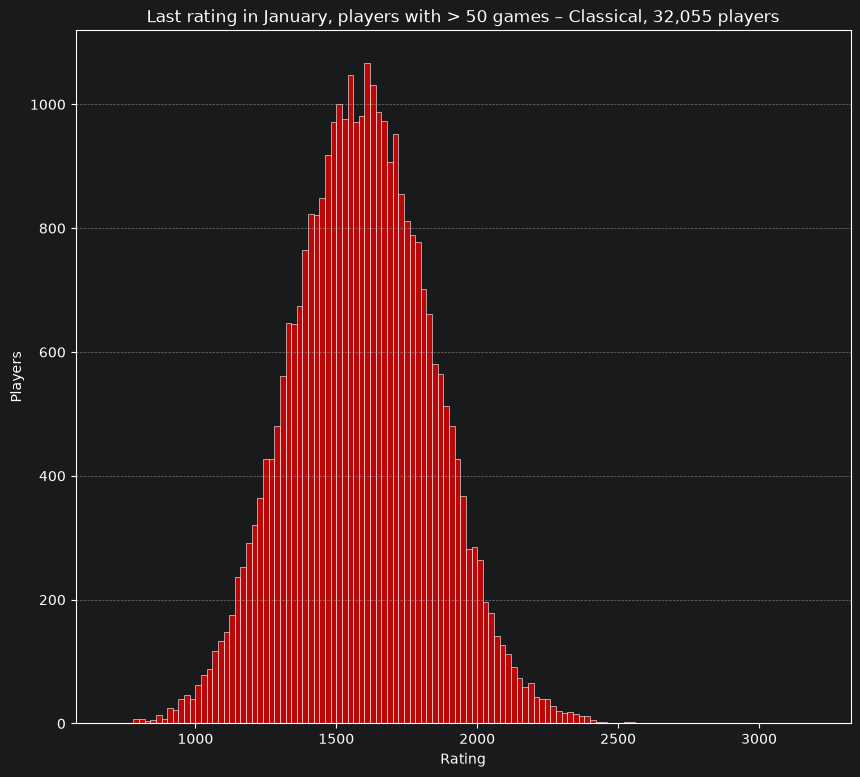

In [15]:
active = last_rating[last_rating["n_games"] > 50]

for speed_type in ["Bullet", "Blitz", "Classical"]:
    sub_df = active[active["speed"] == speed_type].astype({"elo": int})

    plt.figure(figsize=(10, 9))

    sns.histplot(
        data=sub_df,
        x="elo",
        binwidth=20,
        binrange=(700, 3200),
        edgecolor="white",
        color="red",
        alpha=0.7,
    )

    plt.grid(axis="y", linestyle="--", alpha=0.6)
    plt.title(f"Last rating in January, players with > 50 games – {speed_type}, {len(sub_df):,} players")
    plt.xlabel("Rating")
    plt.ylabel("Players")
    plt.show()

In [16]:
print(f"share at exactly 1500 among players with > 50 games: {(active['elo'] == 1500).mean():.2%}")

share at exactly 1500 among players with > 50 games: 0.11%


- 34,020 (9.8%) player-speed pairs have a last rating of exactly 1500, and 33,393 of them played only one game in that speed.
  The rating stored is the rating before the game, so a rating of 1500 means the player's first rated game in that speed. The spike consists of new accounts at the starting rating.


Uncalibrated provisional accounts with less than 50 games should be flagged. `white_provisional` and `black_provisional`.

## Rating differences between pieces

In [17]:
df["elo_diff"] = (df["WhiteElo"] - df["BlackElo"]).astype(int)

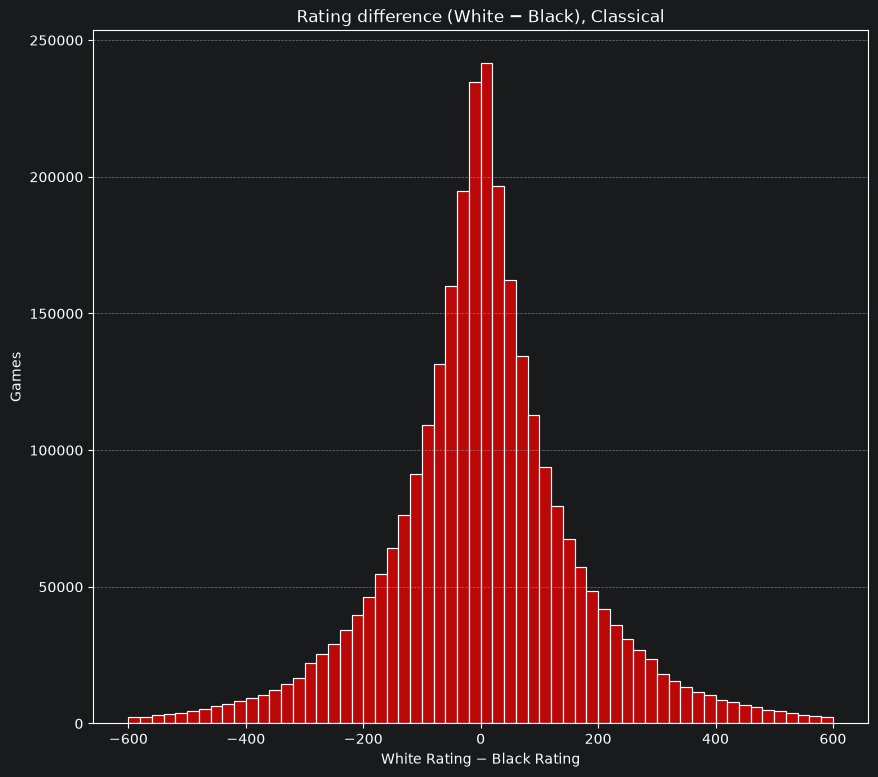

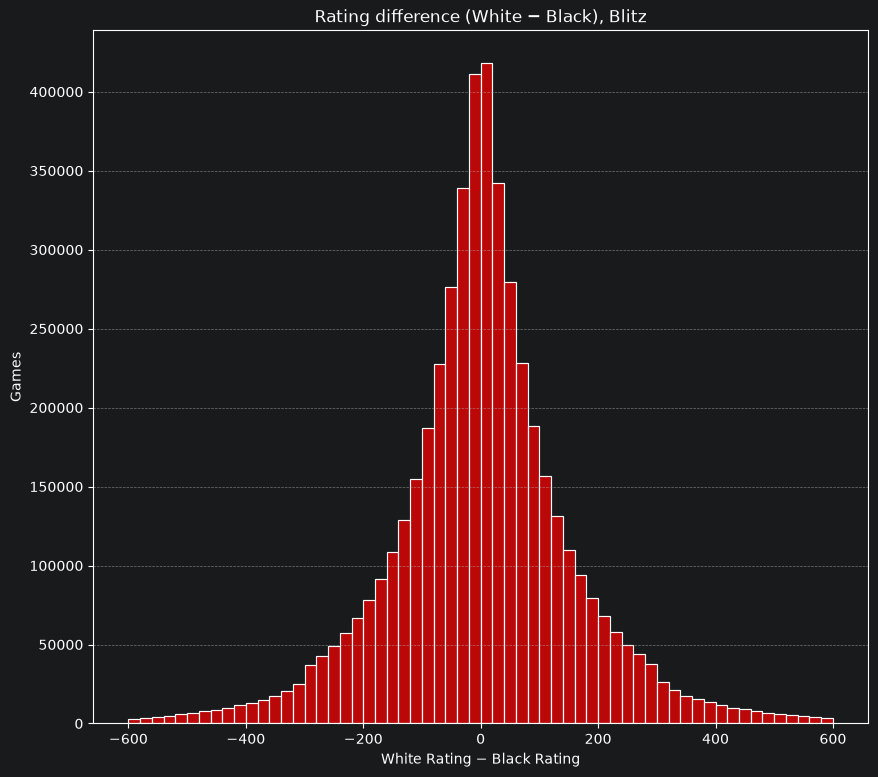

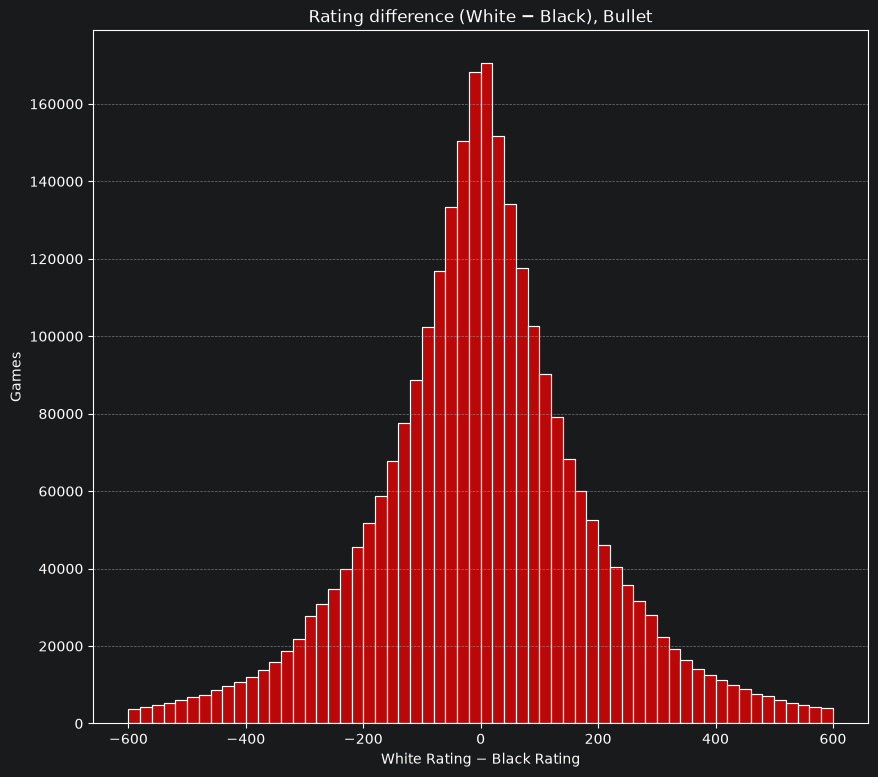

In [18]:
for speed_type in ["Classical", "Blitz", "Bullet"]:
    sub_df=df[df["speed"]==speed_type]

    plt.figure(figsize=(10,9))

    sns.histplot(
        data=sub_df,
        x="elo_diff",
        binwidth=20,
        binrange=(-600, 600),
        edgecolor="white",
        color="red",
        alpha=0.7,
    )

    plt.title(f"Rating difference (White − Black), {speed_type}")
    plt.xlabel("White Rating − Black Rating")
    plt.ylabel("Games")
    plt.grid(axis="y", linestyle="--", alpha=0.6)
    plt.show()

In [19]:
stats = df.groupby("speed")["elo_diff"].agg(
    average="mean",
    median="median"
)
print(stats)

            average  median
speed                      
Blitz      0.637571     0.0
Bullet     0.834289     0.0
Classical  2.600863     1.0


In [20]:
for s in ["Bullet", "Blitz", "Classical"]:
    d = df.loc[df["speed"] == s, "elo_diff"].abs()
    print(f"{s:<10} |diff|<=100: {(d <= 100).mean():.1%}   |diff|>600: {(d > 600).mean():.2%}")

Bullet     |diff|<=100: 49.1%   |diff|>600: 1.82%
Blitz      |diff|<=100: 59.4%   |diff|>600: 0.76%
Classical  |diff|<=100: 57.6%   |diff|>600: 0.82%


The rating difference is centred at zero in every speed, so color assignment does not favor the stronger player.
Pairings are close: 49.1% of Bullet, 59.4% of Blitz and 57.6% of Classical games have a difference of at most 100 ranking points.

## Termination distribution

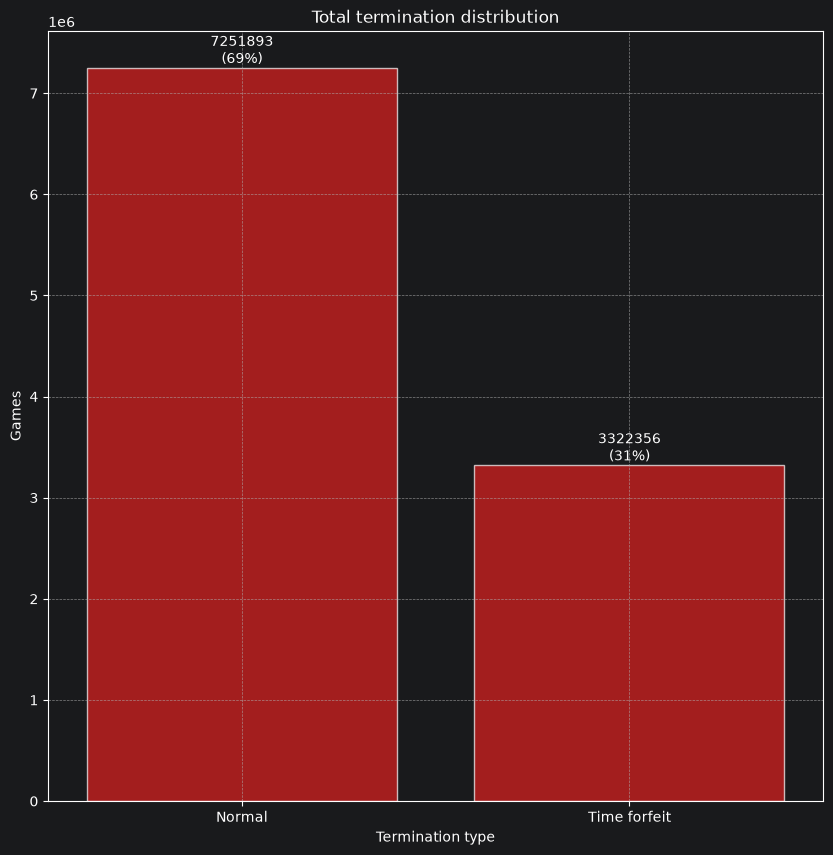

In [21]:
plt.figure(figsize=(10,10))

ax = sns.countplot(
    data=df,
    x="Termination",
    order=df["Termination"].value_counts().index,
    edgecolor="white",
    color="red",
    alpha=0.7,
)

heights = ax.containers[0].datavalues
labels = [f"{int(h)}\n({h / heights.sum():.0%})" for h in heights]
plt.bar_label(ax.containers[0], labels=labels)

plt.grid(axis="both", linestyle="--",alpha=0.7)
plt.title("Total termination distribution")
plt.ylabel("Games")
plt.xlabel("Termination type")
plt.show()

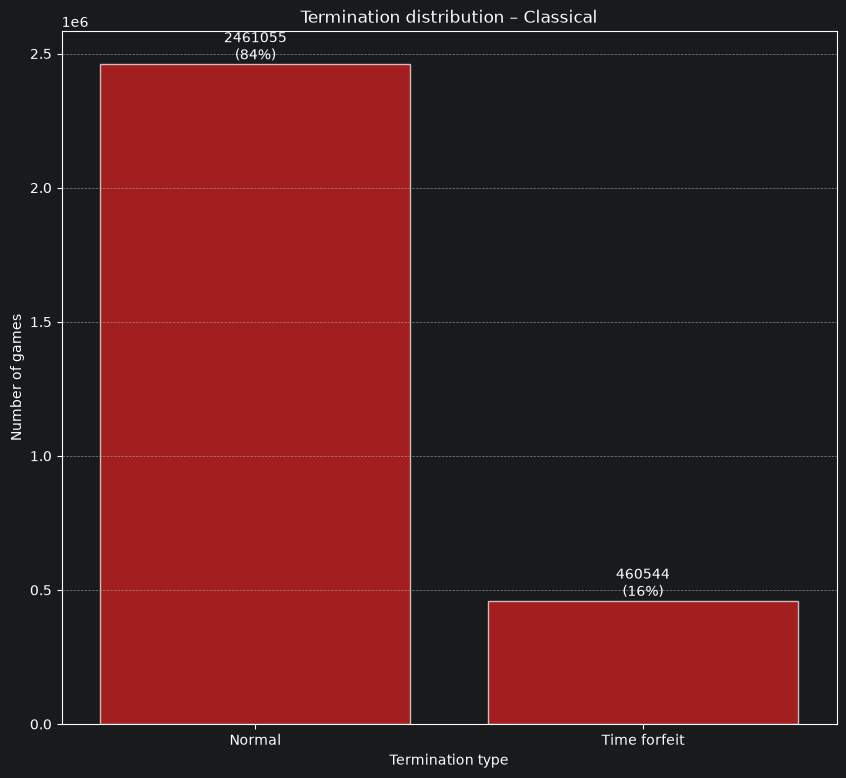

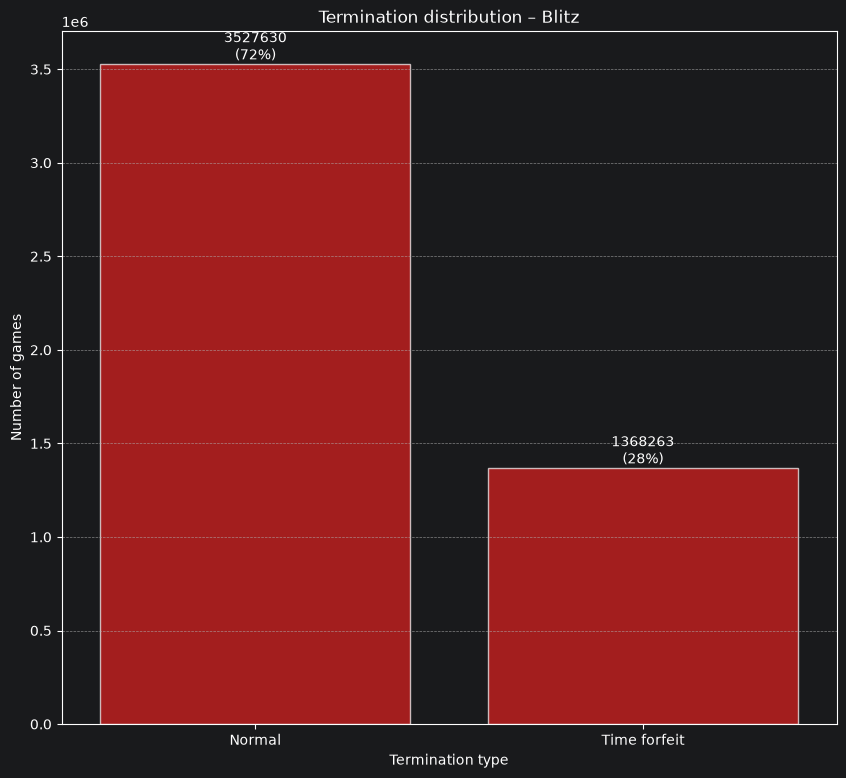

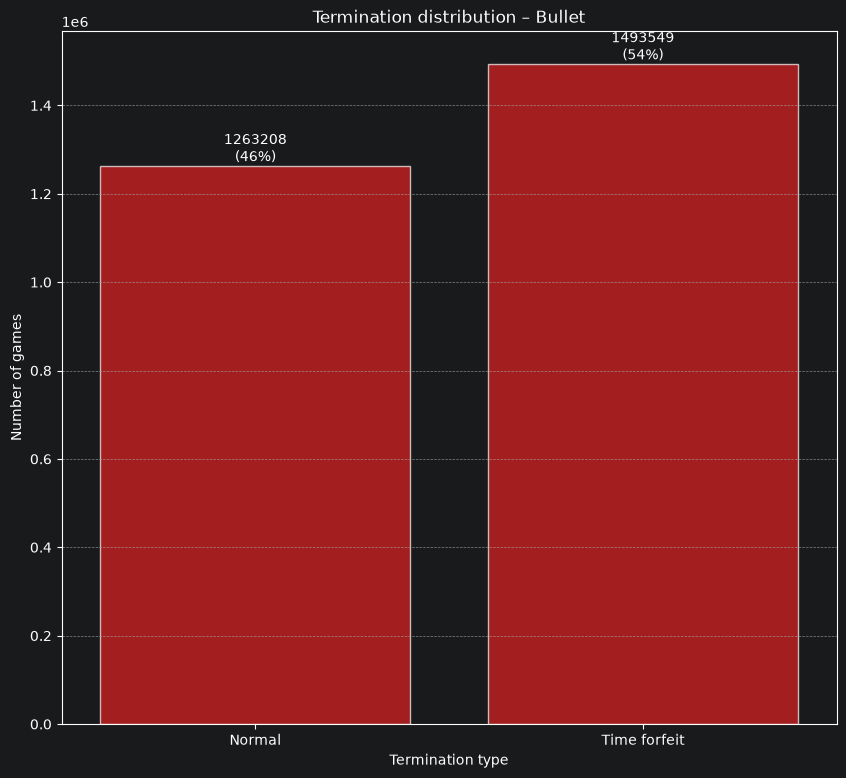

In [22]:
for speed_type in ["Classical", "Blitz", "Bullet"]:
    sub_df = df[df["speed"] == speed_type]

    plt.figure(figsize=(10, 9))

    ax = sns.countplot(
        data=sub_df,
        x="Termination",
        order=["Normal", "Time forfeit"],
        edgecolor="white",
        color="red",
        alpha=0.7,
    )

    heights = ax.containers[0].datavalues
    labels = [f"{int(h)}\n({h / heights.sum():.0%})" for h in heights]
    plt.bar_label(ax.containers[0], labels=labels)

    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.title(f"Termination distribution – {speed_type}")
    plt.xlabel("Termination type")
    plt.ylabel("Number of games")
    plt.show()

The shorter the time control, the larger the share of games lost on time: 54% in Bullet, 28% in Blitz, 16% in Classical.

`time_forfeit` is a usable binary target with a strong dependence on speed.

## Result by speed

In [23]:
pd.crosstab(df["speed"], df["Result"], normalize="index").round(3)

Result,0-1,1-0,1/2-1/2
speed,,,
Blitz,0.462,0.495,0.043
Bullet,0.472,0.497,0.032
Classical,0.458,0.498,0.044


White wins more often than Black in every speed. Draws are rare.

## Completeness of data

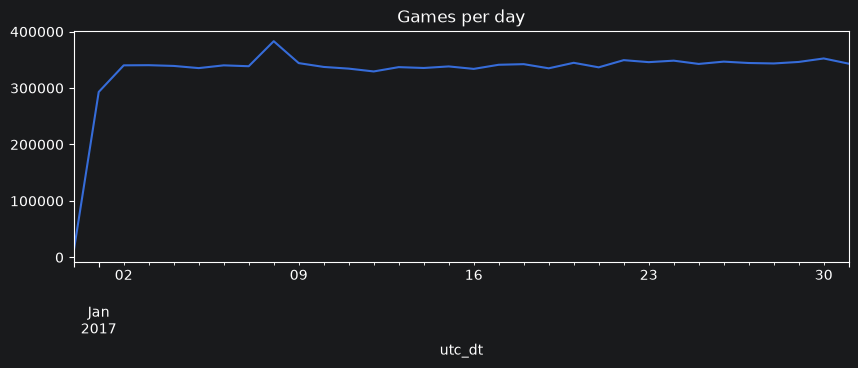

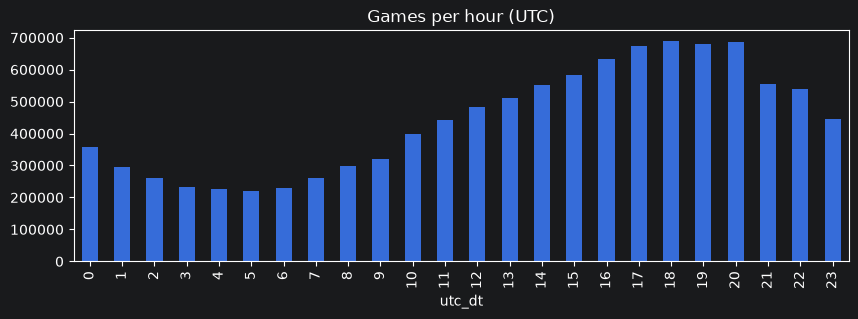

In [24]:
df.set_index("utc_dt").resample("D").size().plot(figsize=(10, 3), title="Games per day")
plt.show()
df["utc_dt"].dt.hour.value_counts().sort_index().plot(kind="bar", figsize=(10, 3), title="Games per hour (UTC)")
plt.show()

In [25]:
daily = df.set_index("utc_dt").resample("D").size()
daily.describe()

count        32.000000
mean     330445.281250
std       59652.155291
min       10808.000000
25%      336403.250000
50%      340363.000000
75%      344456.750000
max      382997.000000
dtype: float64

No sudden drops in the daily number of games. 2016-12-31 contains only its last hour, so its bar is low by construction, not because of missing data.

## Time control labels

In [26]:
tc_counts = df.loc[df["speed"] == "Classical", "TimeControl"].value_counts()
tc_counts[tc_counts > 0]

TimeControl
600+0      1348799
900+0       206594
300+5       138487
300+8       134824
480+0       132576
            ...   
9000+20          1
9000+25          1
9000+4           1
9000+5           1
9000+90          1
Name: count, Length: 798, dtype: int64

In [27]:
tc = df["TimeControl"].astype(str).str.split("+", expand=True).astype(int)
df["base_time"] = tc[0]
df["increment"] = tc[1]
df["est_duration"] = df["base_time"] + 40 * df["increment"]

df.groupby("speed")[["base_time", "increment", "est_duration"]].agg(["min", "max"])

base_time        increment      est_duration       
                min    max       min  max          min    max
speed                                                        
Blitz             0    420         0   11          180    470
Bullet            0    120         0    4           30    170
Classical         0  10800         0  180          480  18000

The most common Classical time controls are 600+0, 900+0, 300+5, 300+8 and 480+0, so time controls that would commonly be called rapid are labelled Classical in this dataset.

## Correlation

In [28]:
corr_df = pd.DataFrame({
    "white_elo": df["WhiteElo"].astype(float),
    "black_elo": df["BlackElo"].astype(float),
    "elo_avg": (df["WhiteElo"] + df["BlackElo"]).astype(float) / 2,
    "elo_diff": df["elo_diff"],
    "base_time": df["TimeControl"].astype(str).str.split("+").str[0].astype(int),
    "increment": df["TimeControl"].astype(str).str.split("+").str[1].astype(int),
    "is_tournament": df["event_type"].str.contains("tournament").astype(int),
    "white_score": df["Result"].astype(str).map({"1-0": 1.0, "1/2-1/2": 0.5, "0-1": 0.0}),
    "time_forfeit": (df["Termination"] == "Time forfeit").astype(int),
})

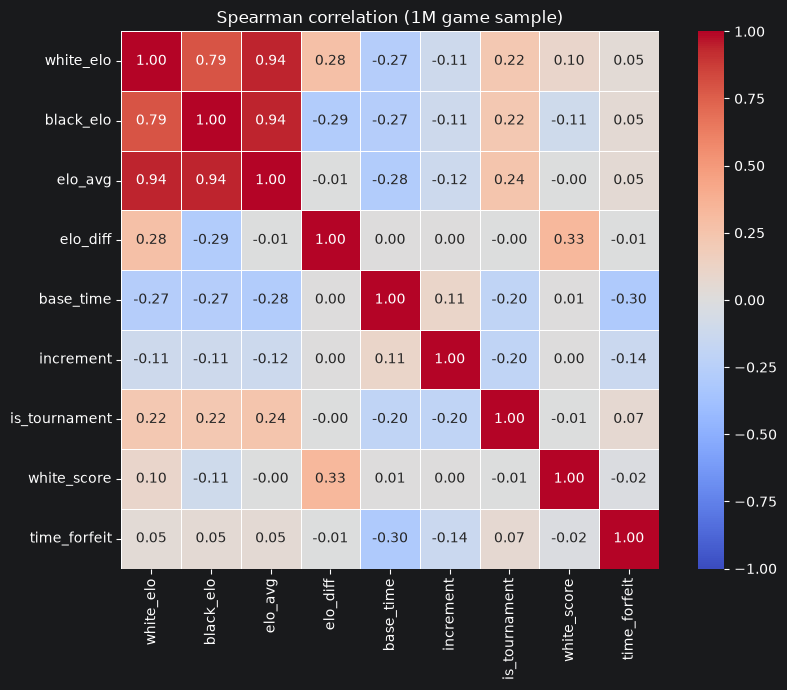

In [29]:
corr = corr_df.sample(1_000_000, random_state=42).corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    square=True,
    ax=ax,
)
ax.set_title("Spearman correlation (1M game sample)")
fig.tight_layout()
plt.show()

In [30]:
corr[["white_score", "time_forfeit"]].drop(index=["white_score", "time_forfeit"]).round(2)

,white_score,time_forfeit
white_elo,0.10,0.05
black_elo,-0.11,0.05
elo_avg,-0.00,0.05
elo_diff,0.33,-0.01
base_time,0.01,-0.30
increment,0.00,-0.14
is_tournament,-0.01,0.07


Some correlations follow from how columns were built and reveal nothing new.